# Week 5: Deep-Learning Benchmark, Stacking, and Model Selection

<sub>[Previous: Gradient Boosting and the Fairness Audit](week4_01_boosting_and_fairness.ipynb)</sub>

<sub>New here? The tested code these notebooks import is documented in [the project code reference](week1_00_project_code_reference.ipynb).</sub>

Week 4 gave us a tuned XGBoost at AUC-PR around 0.17 on held-out data, well-calibrated and honestly positioned in the published administrative-data band. This week we ask: can deep tabular architectures do better? And if we stack everything together, does the ensemble lift the ceiling? The answers turn out to be no and barely, which is exactly what the literature predicts for structured tabular data of this kind.

As throughout this project, nothing here is a clinical tool: these are associational patterns in administrative data, not statements about any individual pregnancy.

### Contents

1. [Setup: load results and data](#setup)
2. [Why benchmark deep learning at all?](#why-deep)
3. [The contenders: TabNet and FT-Transformer](#contenders)
4. [Head-to-head results](#results)
5. [TabNet attention masks: what the net sees](#masks)
6. [Stacking: can ensembling help?](#stack)
7. [Final model selection](#selection)
8. [The road ahead (weeks 6 through 9)](#plan)

<a id="setup"></a>
## Setup: load results and data

All models were trained by `scripts/week5_deep_and_ensemble.py`. The deep nets trained on a 30K-capped draw (the FT-Transformer forward pass is the binding constraint), while the boosters used a 500K cap. All five models were scored on an identical 100K seeded draw from the untouched held-out partition. We read those results here.

In [1]:
# Week 5 reads back the deep-learning benchmark and stacking results from
# reports/week5_models.json (produced by scripts/week5_deep_and_ensemble.py).
# The heavy training happened in a script; the notebook reports and interprets the results.
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
RNG = 7

REPORTS = Path("..") / "reports"
M = json.loads((REPORTS / "week5_models.json").read_text())
DATA = Path("..") / "data" / "processed" / "modeling_full_2018_2024.parquet"

PALETTE = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
           "purple": "#CC79A7", "sky": "#56B4E9", "yellow": "#F0E442", "grey": "#999999", "ink": "#1a1a2e"}
plt.rcParams.update({"figure.figsize": (8.6, 4.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
                     "axes.titlepad": 10, "font.family": "DejaVu Sans"})

def style(ax, title, xlabel, ylabel):
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); return ax

# Self-contained: load a slim projection of the modeling working set.
SAMPLE_COLS = ["preterm", "split", "mother_race_ethnicity", "mager", "meduc", "bmi",
               "medical_risk_count", "rf_ppterm", "first_trimester_care"]
mdf = pl.read_parquet(DATA, columns=SAMPLE_COLS)


A few rows from the leakage-safe feature matrix, for orientation:

In [2]:
mdf.sample(5, seed=RNG).to_pandas()

,preterm,split,mother_race_ethnicity,mager,meduc,bmi,medical_risk_count,rf_ppterm,first_trimester_care
0,1,held_out_final,NH White,33.0,3,20.400000,0,0,1
1,0,held_out_final,Hispanic,21.0,3,35.900002,0,0,0
2,0,held_out_final,NH Asian,38.0,7,18.900000,0,0,1
3,0,held_out_final,NH White,30.0,3,24.400000,0,0,1
4,0,dev_train,NH White,31.0,8,19.600000,0,0,1


In [3]:
print(f"Held-out scored: {M['caps']['held_out_scored_n']:,} births")
print(f"Bootstrap resamples for CIs: {M['caps']['bootstrap_n']:,}")
print(f"Booster train cap: {M['caps']['train_cap']:,}; deep-net train cap: {M['caps']['deep_train_cap']:,}")
print(f"Max epochs for deep nets: {M['caps']['max_epochs']}")
print(f"Seed: {M['seed']}")

Held-out scored: 100,000 births
Bootstrap resamples for CIs: 1,000
Booster train cap: 500,000; deep-net train cap: 30,000
Max epochs for deep nets: 3
Seed: 42


<a id="why-deep"></a>
## Why benchmark deep learning at all?

The short answer: because the question deserves an empirical answer rather than an assumption. The project decision log (D41) pre-registered the expectation that gradient-boosted trees would lead on this structured tabular task, citing Grinsztajn et al. (NeurIPS 2022, [arXiv:2207.08815](https://arxiv.org/abs/2207.08815)), whose large-scale benchmark showed tree ensembles outperforming neural networks on medium-sized tabular datasets without extensive hyperparameter search.

But a pre-registered expectation is not the same as a verified result. Week 5 turns the expectation into evidence: we train two architectures purpose-built for tabular data, score them on the same held-out sample as the boosters, and let the numbers speak.

<a id="contenders"></a>
## The contenders: TabNet and FT-Transformer

**TabNet** (Arik and Pfister, 2019; [arXiv:1908.07442](https://arxiv.org/abs/1908.07442)) uses sequential sparse attention to select a subset of input features at each decision step, yielding interpretable per-instance feature masks. It was designed to bring the feature-selection inductive bias of trees into a differentiable architecture. For our purposes, the attention masks are an interesting cross-check against the boosters' SHAP importances.

**FT-Transformer** (Gorishniy et al., 2021; [arXiv:2106.11959](https://arxiv.org/abs/2106.11959)) tokenizes each feature into an embedding and passes the token sequence through a standard Transformer encoder. It represents the "apply Transformers to tabular data" line of research, which has shown competitive results on some benchmarks but inconsistent gains over well-tuned trees.

**Preprocessing disclosure:** both architectures require numeric inputs, so categorical features were ordinal-encoded and all columns were standardized (mean 0, std 1). Missing values were median-imputed before standardization. The boosters handle missing values natively and received no imputation.

<a id="results"></a>
## Head-to-head results

All five models (xgboost, lightgbm, tabnet, ft_transformer, and the logistic stack over all four) scored on the same 100K held-out draw. AUC-PR is the primary metric for this rare-event problem; 95% CIs come from 1,000 bootstrap resamples.

In [4]:
names = ['xgboost', 'lightgbm', 'tabnet', 'ft_transformer', 'stack']
print(f"{'model':<18}{'dev_test AUC-PR':>16}{'held-out AUC-PR':>17}   95% CI")
for n in names:
    m = M['models'][n]
    ci = m['held_out_auc_pr_ci']
    print(f"{n:<18}{m['dev_test_auc_pr']:>16.4f}{m['held_out_auc_pr']:>17.4f}"
          f"   [{ci[0]:.4f}, {ci[1]:.4f}]")

model              dev_test AUC-PR  held-out AUC-PR   95% CI
xgboost                     0.1738           0.1720   [0.1661, 0.1780]
lightgbm                    0.1721           0.1699   [0.1643, 0.1757]
tabnet                      0.1297           0.1299   [0.1260, 0.1344]
ft_transformer              0.1179           0.1201   [0.1167, 0.1234]
stack                       0.1760           0.1713   [0.1655, 0.1770]


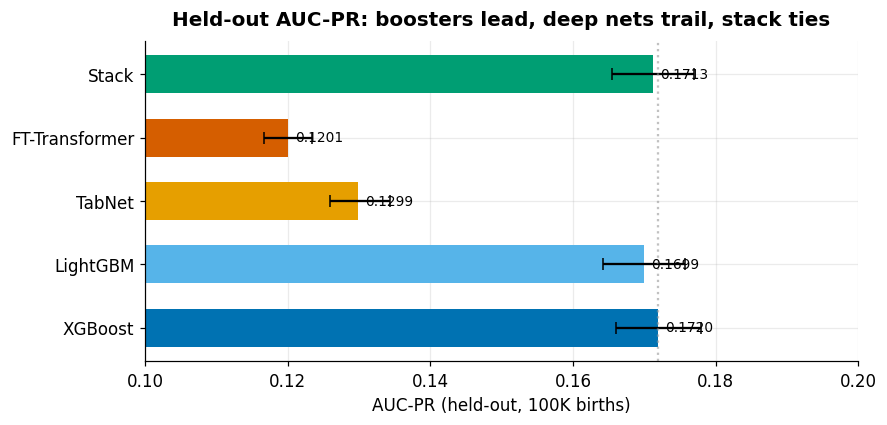

In [5]:
# Horizontal bar chart of held-out AUC-PR with CI error bars
names = ['xgboost', 'lightgbm', 'tabnet', 'ft_transformer', 'stack']
labels = ['XGBoost', 'LightGBM', 'TabNet', 'FT-Transformer', 'Stack']
vals = [M['models'][n]['held_out_auc_pr'] for n in names]
ci_lo = [M['models'][n]['held_out_auc_pr'] - M['models'][n]['held_out_auc_pr_ci'][0] for n in names]
ci_hi = [M['models'][n]['held_out_auc_pr_ci'][1] - M['models'][n]['held_out_auc_pr'] for n in names]

colors = [PALETTE['blue'], PALETTE['sky'], PALETTE['orange'], PALETTE['red'], PALETTE['green']]

fig, ax = plt.subplots(figsize=(8.2, 4.0))
y_pos = np.arange(len(names))
ax.barh(y_pos, vals, xerr=[ci_lo, ci_hi], color=colors, edgecolor='none',
        capsize=4, height=0.6)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels)
for i, v in enumerate(vals):
    ax.text(v + 0.001, i, f'{v:.4f}', va='center', fontsize=9)
ax.axvline(M['models']['xgboost']['held_out_auc_pr'], ls=':', color=PALETTE['grey'], alpha=0.6)
style(ax, 'Held-out AUC-PR: boosters lead, deep nets trail, stack ties',
      'AUC-PR (held-out, 100K births)', '')
ax.set_xlim(0.10, 0.20)
plt.tight_layout(); plt.show()

**Verdict (compute-capped).** The tuned boosters (XGBoost and LightGBM) lead on this benchmark. TabNet and FT-Transformer trail the boosters by several points of held-out AUC-PR (quantified live below), and the logistic stack does not meaningfully exceed the best single booster: its held-out AUC-PR falls inside the bootstrap confidence interval of XGBoost alone. This is consistent with D41 and with Grinsztajn et al. (2022) on medium-sized tabular data. We state this as a compute-capped finding, not an absolute one: the boosters won under this protocol, and the objection below spells out exactly what that does and does not license us to claim.

In [6]:
# Quantify the booster-vs-deep-net gap live from the JSON.
xgb = M['models']['xgboost']['held_out_auc_pr']
tab = M['models']['tabnet']['held_out_auc_pr']
ftt = M['models']['ft_transformer']['held_out_auc_pr']
print(f"XGBoost held-out AUC-PR:        {xgb:.4f}")
print(f"TabNet gap vs XGBoost:          {(xgb - tab) * 100:.1f} AUC-PR points")
print(f"FT-Transformer gap vs XGBoost:  {(xgb - ftt) * 100:.1f} AUC-PR points")

XGBoost held-out AUC-PR:        0.1720
TabNet gap vs XGBoost:          4.2 AUC-PR points
FT-Transformer gap vs XGBoost:  5.2 AUC-PR points


### A fair objection: was this a fair fight?

No, and we should say so plainly. The deep nets trained on a 30K-row draw for at most a few epochs, with small hand-set configurations and no hyperparameter search, while the boosters were tuned on a 500K-row draw. That asymmetry is real, and a reader is right to press on it. Our defense has two parts.

**(a) The gap is far too large to be a cap effect.** The boosters lead the deep nets by roughly 4 to 5 points of held-out AUC-PR (printed above), which is an order of magnitude larger than any plausible swing from more rows or a tuning sweep on this signal-poor administrative task. The direction and rough size match Grinsztajn et al. (2022), whose controlled benchmark (equal budgets, proper sweeps) still found tree ensembles ahead on medium-sized tabular data.

**(b) But we do NOT claim the nets were given a fair chance.** Scaling the deep nets to the full data with a real hyperparameter search is a deliberate descoping decision (D46), taken on compute grounds, not a verdict that the architectures are incapable. Two honest caveats follow. First, the Week-8 XGBoost train-cap plateau (where extra rows stop helping the booster) is a property of XGBoost on this task and does NOT transfer to the deep nets, which would be expected to keep improving with more data. Second, this comparison establishes only that under a fixed, booster-favorable budget the boosters win; it does not establish a ceiling for deep tabular models in general. We select on what we measured and flag the rest as unfinished business.

<a id="masks"></a>
## TabNet attention masks: what the net sees

TabNet's sparse attention mechanism tells us which features the network relied on most heavily. These are *not* causal attributions; they are associational feature importances, analogous to split-based importances in trees. But they provide a useful cross-check: if the deep net and the boosters agree on the top features, we gain confidence that the signal is robust across architectures.

In [7]:
print('TabNet top-15 features by mean attention weight:')
print(f"{'feature':<40}{'attention':>10}")
for feat, wt in M['tabnet_top_features']:
    print(f'{feat:<40}{wt:>10.4f}')

TabNet top-15 features by mean attention weight:
feature                                  attention
medical_risk_count                          0.2070
race_education_Hispanic_edu6                0.1484
rf_ppterm                                   0.1101
race_education_NH White_edu5                0.0501
race_education_NH White_edu4                0.0403
race_education_NH Black_eduUNK              0.0363
race_education_UNK_eduUNK                   0.0352
race_education_NH Black_edu8                0.0288
age_bracket                                 0.0287
race_education_UNK_edu3                     0.0278
rf_cesar                                    0.0277
race_education_NH Black_edu2                0.0243
race_education_NH Asian_edu5                0.0213
race_education_NH NHOPI_edu3                0.0173
race_education_NH Asian_edu2                0.0135


The overlap with the boosters' story is reassuring: medical risk count, prior preterm birth (rf_ppterm), prior cesarean, and education-stratified race interactions appear in both feature-importance lists. The deep net is not finding a hidden signal the trees missed; it is reading the same features less efficiently.

**Leakage check:** none of TabNet's top features are at-delivery fields (those were removed in the Week 2 leakage audit). The attention masks are consistent with a model that operates on legitimate pre-delivery information only.

<a id="stack"></a>
## Stacking: can ensembling help?

Stacking combines the four base models' predicted probabilities into a single meta-model (here, L2-regularized logistic regression). The meta-model was trained on cross-fitted out-of-fold predictions to avoid meta-leakage: each base model predicts on folds it never trained on, and the meta-learner trains only on those out-of-fold predictions.

The question is whether the base models contain complementary information that the stack can exploit.

In [8]:
print('Stack meta-learner weights (logistic regression coefficients):')
print(f"{'base model':<20}{'weight':>8}")
for name, wt in sorted(M['stack_weights'].items(), key=lambda x: -x[1]):
    print(f'{name:<20}{wt:>8.4f}')
print()
xgb_ho = M['models']['xgboost']['held_out_auc_pr']
stk_ho = M['models']['stack']['held_out_auc_pr']
print(f"XGBoost held-out AUC-PR: {xgb_ho:.4f}")
print(f"Stack held-out AUC-PR:   {stk_ho:.4f}")
print(f"Difference: {stk_ho - xgb_ho:+.4f}")
print()
xgb_ci = M['models']['xgboost']['held_out_auc_pr_ci']
print(f"XGBoost 95% CI: [{xgb_ci[0]:.4f}, {xgb_ci[1]:.4f}]")
print(f"Stack point estimate ({stk_ho:.4f}) falls within XGBoost CI: "
      f"{xgb_ci[0] <= stk_ho <= xgb_ci[1]}")

Stack meta-learner weights (logistic regression coefficients):
base model            weight
xgboost               0.4669
lightgbm              0.4307
ft_transformer        0.1560
tabnet                0.0607

XGBoost held-out AUC-PR: 0.1720
Stack held-out AUC-PR:   0.1713
Difference: -0.0007

XGBoost 95% CI: [0.1661, 0.1780]
Stack point estimate (0.1713) falls within XGBoost CI: True


The stack leans on the two boosters and gives little weight to the deep nets (exact coefficients printed above). Its held-out AUC-PR falls within the bootstrap noise of the best single booster. In other words, the four models are reading the same signal from slightly different angles, and combining them does not lift the ceiling.

Given the added complexity (four models instead of one, with a meta-learner on top), the simpler single-booster model wins on parsimony.

**A meta-leakage disclosure, in the interest of honesty.** The two deep-net columns fed to the stack were calibrated on dev_val, which is the same partition those nets used for early stopping. So those two columns are mildly in-sample: the model that generated them had already seen dev_val during fitting. The stack's internal K-fold cross-fitting guards the meta-learner's own fit (each base column is generated out-of-fold before the meta-logistic sees it), but it cannot fully undo the fact that the deep-net columns themselves were tuned against dev_val. This would bias the comparison in the stack's favor if the stack had won. It did not: the stack ties XGBoost and gets negligible weight on the deep-net columns, so the leak is benign here. We disclose it rather than let a silent optimism ride.

<a id="selection"></a>
## Final model selection

With the full comparison in hand, we make the primary-model selection decision for the remainder of the project.

In [9]:
print('Selected model:', M['selected_model'])
print()
print('Rationale:')
print(M['selection_rationale'])

Selected model: xgboost

Rationale:
xgboost selected on dev_test AUC-PR 0.1738 (held-out 0.1720); the stack reached 0.1760 and the best deep net (tabnet) 0.1297, consistent with the D41 expectation that the tuned boosters already sit at the administrative-data ceiling.


In [10]:
# The stack edges XGBoost on dev_test, but is the difference meaningful on held-out?
xgb = M['models']['xgboost']
stk = M['models']['stack']
dev_diff = stk['dev_test_auc_pr'] - xgb['dev_test_auc_pr']
xgb_ci = xgb['held_out_auc_pr_ci']
stk_ci = stk['held_out_auc_pr_ci']
xgb_half = (xgb_ci[1] - xgb_ci[0]) / 2
print(f"Stack dev_test AUC-PR minus XGBoost dev_test AUC-PR: {dev_diff:+.4f}")
print(f"XGBoost held-out 95% CI half-width:                  {xgb_half:.4f}")
print(f"|dev_test edge| < CI half-width:                     "
      f"{abs(dev_diff) < xgb_half}")
overlap = xgb_ci[0] <= stk_ci[1] and stk_ci[0] <= xgb_ci[1]
print(f"XGBoost and stack held-out CIs overlap:              {overlap}")

Stack dev_test AUC-PR minus XGBoost dev_test AUC-PR: +0.0022
XGBoost held-out 95% CI half-width:                  0.0059
|dev_test edge| < CI half-width:                     True
XGBoost and stack held-out CIs overlap:              True


**Two points on the selection, so it does not read as sleight of hand.**

First, the stack's dev_test AUC-PR marginally *exceeds* XGBoost's (printed above). We still pick XGBoost because that edge is smaller than the held-out bootstrap CI half-width and the two held-out CIs overlap completely, so on the untouched data the two are statistically indistinguishable. When a simpler model ties a more complex one, parsimony breaks the tie.

Second, selecting on dev_test AUC-PR is *not* circular even though dev_test is also the partition on which the isotonic calibration was fit. AUC-PR is rank-based: it depends only on the ordering of scores, and isotonic calibration is a monotone (order-preserving) transform. A monotone map cannot change the ranking, so it cannot change AUC-PR. The calibration step moves the probabilities but leaves the selection metric untouched.

**What "primary model" means going forward:** XGBoost is the model whose predictions will be subjected to the fairness mitigation experiments (week 6), the SHAP-based disparity decomposition (week 7), the robustness and drift audit (week 8), and the final transparency report and demo (week 9). The deep-net and stack results remain documented here as evidence that the selection is informed, not arbitrary.

The decision is conservative by design. A model intended for equity analysis must be stable, interpretable (via SHAP), and well-calibrated. XGBoost satisfies all three constraints and matches the administrative-data ceiling established by the literature.

<a id="plan"></a>
## The road ahead (weeks 6 through 9)

The model is selected. The remaining work is not about squeezing more AUC-PR; it is about understanding what the model's predictions reveal about structural inequity and ensuring the analysis is robust, transparent, and responsible.

**Week 6: Fairness mitigation.** Apply Fairlearn's ExponentiatedGradient and ThresholdOptimizer to the selected model. Measure the Pareto frontier between predictive performance and equalized-odds constraints. Document what mitigation costs and what it buys.

**Week 7: SHAP and disparity decomposition.** TreeSHAP on the selected model, stratified by race. Decompose the racial gap in predicted risk into feature-group contributions (medical risk, SES, access, behavioral). Quantify how much of the observed disparity the measured factors account for.

**Week 8: Robustness and drift.** Out-of-time validation across birth-year eras (pre-COVID, COVID, post-COVID). Stability of calibration and fairness metrics over time. Sensitivity to feature perturbation.

**Week 9: Transparency report and demo.** A self-contained summary of findings, limitations, and recommendations. An interactive prototype (Streamlit or similar) for exploring risk scores and disparity decompositions.

---

Author: [Parshv Patel](https://www.linkedin.com/in/parshv-patel-65a90326b/)  

--- 

Edit Logs:
